# **Part 1: TF-IDF by Hand** 

In [14]:
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
 ConfusionMatrixDisplay, f1_score)
nlp = spacy.load('en_core_web_sm') # preinstalled on Kaggle
print('spaCy', spacy.__version__)
docs = ['win free cash now', 'call me now', 'free call now']
vec = TfidfVectorizer() # smooth idf + L2 normalization
X = vec.fit_transform(docs)
print(pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(),
 index=['d1', 'd2', 'd3']).round(3))
# Reproduce d1 by hand: idf = ln((1 + N) / (1 + df)) + 1
N = 3
idf = {'win': np.log(4 / 2) + 1, 'free': np.log(4 / 3) + 1,
 'cash': np.log(4 / 2) + 1, 'now': np.log(4 / 4) + 1}
v = np.array(list(idf.values())) # tf = 1 for each word in d1
print({w: round(x, 3) for w, x in zip(idf, v / np.linalg.norm(v))})

spaCy 3.8.16
     call   cash   free    me    now    win
d1  0.000  0.584  0.445  0.00  0.345  0.584
d2  0.548  0.000  0.000  0.72  0.425  0.000
d3  0.620  0.000  0.620  0.00  0.481  0.000
{'win': np.float64(0.584), 'free': np.float64(0.445), 'cash': np.float64(0.584), 'now': np.float64(0.345)}


### Write it: Show the IDF arithmetic for "free" and "now". Why does "now" get the lowest weight?Compute the cosine similarity between d2 and d3 from the printed table (multiply matching entries and add) and compare with 0.54.

IDF (smooth: ln((1+N)/(1+df)) + 1, N = 3):
- "free" is in 2 of 3 documents: ln(4/3) + 1 = 0.288 + 1 = 1.288
- "now" is in 3 of 3 documents: ln(4/4) + 1 = 1.000

"now" gets the lowest weight because it appears in every document, so it cannot help tell documents apart. Smooth IDF keeps it at 1.0 instead of 0, so it is down-weighted, not removed.

Cosine of d2 and d3: call 0.548 x 0.620 = 0.340, now 0.425 x 0.481 = 0.204. Sum = 0.544, matching the 0.54 on slide 10. My hand-computed d1 (win 0.584, free 0.445, cash 0.584, now 0.345) was identical to scikit-learn.

# **Part 2: Text Classification**

In [25]:
path = '/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv'
sms = pd.read_csv(path, encoding='latin-1')[['v1', 'v2']]
sms.columns = ['label', 'text']
sms['y'] = (sms['label'] == 'spam').astype(int)
print(sms['label'].value_counts().to_string())
print(f"Spam share: {sms['y'].mean():.3f} "
 f"'always ham' accuracy: {1 - sms['y'].mean():.3f}")

label
ham     4825
spam     747
Spam share: 0.134 'always ham' accuracy: 0.866


              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115



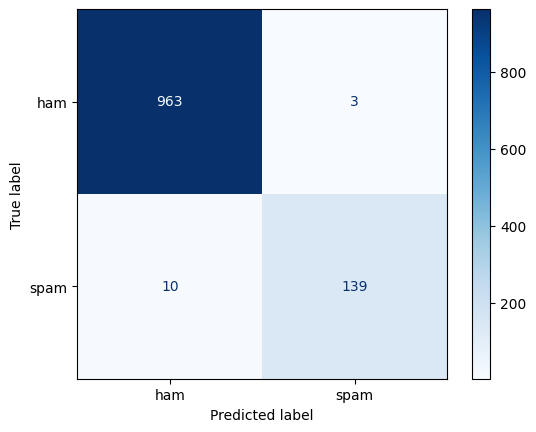

In [27]:
X_tr, X_te, y_tr, y_te = train_test_split(
 sms['text'], sms['y'], test_size=0.2, random_state=42,
 stratify=sms['y'])
word_clf = Pipeline([
 ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2,
 sublinear_tf=True)),
 ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
word_clf.fit(X_tr, y_tr)
pred = word_clf.predict(X_te)
print(classification_report(y_te, pred, target_names=['ham', 'spam'],
 digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
 display_labels=['ham', 'spam']).plot(cmap='Blues')
plt.show()

In [29]:
tf = word_clf.named_steps['tfidf']
w = word_clf.named_steps['model'].coef_[0]
terms = tf.get_feature_names_out()
order = np.argsort(w)
print('Most spam-like :', list(terms[order[-12:]][::-1]))
print('Most ham-like :', list(terms[order[:12]]))

Most spam-like : ['call', 'txt', 'free', 'text', 'reply', 'uk', 'to', 'www', 'mobile', 'claim', 'stop', 'your']
Most ham-like : ['my', 'me', 'ok', 'that', 'it', 'but', 'll', 'gt', 'lt', 'can', 'what', 'da']


In [31]:
char_clf = Pipeline([
 ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
 min_df=2, sublinear_tf=True)),
 ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
char_clf.fit(X_tr, y_tr)
for name, clf in [('word 1-2 grams', word_clf), ('char 2-5 grams', char_clf)]:
 p = clf.predict(X_te)
 print(f'{name:15s} macro-F1 {f1_score(y_te, p, average="macro"):.3f} '
 f'features {len(clf.named_steps["tfidf"].vocabulary_):,}')
# Robustness to spelling tricks
tricky = ['W1N a FR33 pr1ze!! txt CLAIM now', 'kal milte hain, 5 baje']
print(dict(zip(tricky, char_clf.predict_proba(tricky)[:, 1].round(2))))

word 1-2 grams  macro-F1 0.974 features 12,128
char 2-5 grams  macro-F1 0.982 features 36,449
{'W1N a FR33 pr1ze!! txt CLAIM now': np.float64(0.85), 'kal milte hain, 5 baje': np.float64(0.12)}


In [32]:
p_te = word_clf.predict_proba(X_te)[:, 1]
err = pd.DataFrame({'text': X_te, 'true': y_te, 'p_spam': p_te})
err = err[(err.p_spam >= 0.5) != (err.true == 1)]
pd.set_option('display.max_colwidth', 90)
print(err.sort_values('p_spam').to_string())

                                                                                                                                                                                       text  true    p_spam
750                                                                                  Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?     1  0.087598
2246  Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get further prem rate msg/subscription. Other nos used also. Beware!     1  0.144048
3979                                                                                                                                                                     ringtoneking 84484     1  0.192426
1429                                                                                                                For sale - arsenal dartboard. Good condition but no doubles or trebl

### Write it: Report macro-F1 and spam precision and recall for both models. Are the top features sensible, or do any look like shortcuts? Classify each misclassified message as model error, label error, or genuinely ambiguous. Write two tricky messages of your own (Roman Urdu or disguised spam) and report how each model scores them.

Data: 5,572 SMS, 747 spam (13.4%). "Always ham" scores 0.866 accuracy and catches no spam.

| Model | Features | Macro-F1 | Spam precision | Spam recall |
|---|---|---|---|---|
| Word 1-2 grams | 12,128 | 0.974 | 0.979 | 0.933 |
| Char 2-5 grams | 36,449 | 0.982 | 0.986 | 0.953 |

The char model is better on all three measures, at three times the features. The word model made 13 errors on 1,115 test messages (10 spam missed, 3 ham flagged); the char model made roughly 9 (about 7 missed, 2 flagged, from its recall values).

Top features: mostly sensible on the spam side (call, txt, free, text, reply, claim, stop, mobile, www). Some look like shortcuts: "to" and "your" are ordinary words that probably reflect the style of spam, and "uk" is a quirk of this dataset. On the ham side, "gt" and "lt" are leftovers of HTML-escaped characters, not meaningful words.

Error analysis of the word model's 13 errors:
- Model errors: 3979 (ringtoneking 84484), 2821 (ROMCAPspam horoscope), 5 (FreeMsg ... std chgs), 2351 (ringtones, Txt to 80082), 1268 (Call me NOW on 09096102316), 152 ("Ok... Ur typical reply..."), 573 ("Waiting for your call." flagged, probably because "call" and "your" are strong spam features).
- Likely label errors: 750 (old ladies and tattoos) and 1429 (dartboard for sale) read like ordinary messages.
- Genuinely ambiguous: 2246 (a warning about a scam), 3358 (missed call with a callback number), 5449 (news joke), 5044 (job ad).

Tricky messages (spam probability):
| Message | Word | Char |
|---|---|---|
| W1N a FR33 pr1ze!! txt CLAIM now | 0.99 | 0.85 |
| kal milte hain, 5 baje | 0.19 | 0.12 |
| Aap ka Jazz number mein Rs. 50000 jeet gaya, abhi call karein (my Roman Urdu prize scam) | 0.50 | 0.37 |
| Y0ur acc0unt is l0cked, verify n0w at b4nk-secure.com (my disguised bank scam) | 0.44 | 0.31 |

Both models flag the lab's spelling-trick message and correctly leave the harmless Roman Urdu message alone. On my two scam messages the word model sits right on the 0.5 threshold for the first and misses the second, and the char model misses both. I expected char n-grams to be more robust, but here they scored lower. A likely reason is that the training data is English SMS, so Roman Urdu and bank-phishing wording is out of distribution for both. Lowering the threshold would catch more scams at the cost of more false alarms on real messages.

# **Part 3: Named Entity Recognition, Measured**

In [7]:
sentences = [
    'Dr. Sana Malik at Shifa International Hospital reviewed the chest X-ray on 14 October 2026.',
    'Muhammad Usman, aged 6, was admitted to Holy Family Hospital Rawalpindi with fever and cough.',
    'The pathology lab charged Rs. 3,500 for the blood test on 02/10/2026.',
    'Nurse Fatima Noor referred the patient to Rawalpindi Institute of Cardiology on Friday.',
    'Please call Dr. Kamran Ali at 0321-5557788 or email kamran.ali@shifa.com.pk.',

    'Dr. Bilal Ahmed at Benazir Bhutto Hospital ordered a repeat scan on 21/10/2026.',
    'The family paid PKR 12,000 to Chughtai Lab in Lahore.',
    'Zainab Bibi from Attock was seen at Fauji Foundation Hospital on Monday.',
    'A follow-up appointment is booked at Aga Khan University Hospital Karachi for 5 November 2026.',
    'Dr. Hira Tariq of Pakistan Institute of Medical Sciences prescribed amoxicillin costing Rs. 850.']
for s in sentences:
 doc = nlp(s)
 print([(e.text, e.label_) for e in doc.ents])

[('Sana Malik', 'PERSON'), ('Shifa International Hospital', 'ORG'), ('14 October 2026', 'DATE')]
[('Muhammad Usman', 'PERSON'), ('6', 'DATE'), ('Holy Family Hospital Rawalpindi', 'ORG')]
[('3,500', 'CARDINAL'), ('02/10/2026', 'ORG')]
[('Nurse Fatima Noor', 'ORG'), ('Rawalpindi Institute of Cardiology', 'ORG'), ('Friday', 'DATE')]
[('Kamran Ali', 'PERSON')]
[('Bilal Ahmed', 'PERSON'), ('Benazir Bhutto Hospital', 'ORG'), ('21/10/2026', 'CARDINAL')]
[('Chughtai Lab', 'PERSON'), ('Lahore', 'GPE')]
[('Zainab Bibi', 'PERSON'), ('Attock', 'PERSON'), ('Fauji Foundation Hospital', 'ORG'), ('Monday', 'DATE')]
[('Aga Khan University Hospital Karachi', 'ORG'), ('5 November 2026', 'DATE')]
[('Hira Tariq', 'PERSON'), ('Pakistan Institute of Medical Sciences', 'ORG'), ('850', 'CARDINAL')]


In [12]:
gold = [
    # rule-writing set (1 to 5)
    {('Sana Malik', 'PERSON'), ('Shifa International Hospital', 'ORG'),
     ('14 October 2026', 'DATE')},
    {('Muhammad Usman', 'PERSON'), ('Holy Family Hospital', 'ORG'),
     ('Rawalpindi', 'GPE')},
    {('Rs. 3,500', 'MONEY'), ('02/10/2026', 'DATE')},
    {('Fatima Noor', 'PERSON'), ('Rawalpindi Institute of Cardiology', 'ORG'),
     ('Friday', 'DATE')},
    {('Kamran Ali', 'PERSON')},
    # held-out set (6 to 10)
    {('Bilal Ahmed', 'PERSON'), ('Benazir Bhutto Hospital', 'ORG'),
     ('21/10/2026', 'DATE')},
    {('PKR 12,000', 'MONEY'), ('Chughtai Lab', 'ORG'), ('Lahore', 'GPE')},
    {('Zainab Bibi', 'PERSON'), ('Attock', 'GPE'),
     ('Fauji Foundation Hospital', 'ORG'), ('Monday', 'DATE')},
    {('Aga Khan University Hospital', 'ORG'), ('Karachi', 'GPE'),
     ('5 November 2026', 'DATE')},
    {('Hira Tariq', 'PERSON'),
     ('Pakistan Institute of Medical Sciences', 'ORG'), ('Rs. 850', 'MONEY')},
]
def ner_scores(nlp_model):
 tp = fp = fn = 0
 for s, g in zip(sentences, gold):
     pred = {(e.text, e.label_) for e in nlp_model(s).ents}
     tp += len(pred & g) # exact text AND label
     fp += len(pred - g)
     fn += len(g - pred)
 p, r = tp / (tp + fp), tp / (tp + fn)
 return {'precision': round(p, 3), 'recall': round(r, 3),
 'f1': round(2 * p * r / (p + r), 3)}
print('spaCy out of the box:', ner_scores(nlp))

def ner_scores_on(nlp_model, sents, gold_sets):
    tp = fp = fn = 0
    for s, g in zip(sents, gold_sets):
        pred = {(e.text, e.label_) for e in nlp_model(s).ents}
        tp += len(pred & g); fp += len(pred - g); fn += len(g - pred)
    p = tp / (tp + fp) if tp + fp else 0
    r = tp / (tp + fn) if tp + fn else 0
    f = 2 * p * r / (p + r) if p + r else 0
    return {'precision': round(p, 3), 'recall': round(r, 3), 'f1': round(f, 3)}

nlp_base = spacy.load('en_core_web_sm')   # fresh, no ruler
print('before, dev :', ner_scores_on(nlp_base, sentences[:5], my_gold[:5]))
print('before, held:', ner_scores_on(nlp_base, sentences[5:], my_gold[5:]))

spaCy out of the box: {'precision': 0.615, 'recall': 0.571, 'f1': 0.593}
before, dev : {'precision': 0.583, 'recall': 0.583, 'f1': 0.583}
before, held: {'precision': 0.643, 'recall': 0.562, 'f1': 0.6}


In [18]:
nlp_rules = spacy.load('en_core_web_sm')
ruler = nlp_rules.add_pipe('entity_ruler', before='ner')
ruler.add_patterns([
    # currency prefix + number (sentence 3: "Rs. 3,500")
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                    {'IS_PUNCT': True, 'OP': '?'},
                                    {'LIKE_NUM': True}]},
    # dd/mm/yyyy (sentence 3: tagged ORG out of the box)
    {'label': 'DATE', 'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
    # "<Title Case words> Hospital" (sentences 1 and 2)
    {'label': 'ORG', 'pattern': [{'IS_TITLE': True, 'OP': '+'}, {'LOWER': 'hospital'}]},
    # gazetteer entries from sentences 1-5
    {'label': 'ORG', 'pattern': 'Rawalpindi Institute of Cardiology'},
    {'label': 'GPE', 'pattern': 'Rawalpindi'},
    {'label': 'PERSON', 'pattern': 'Fatima Noor'},
])

print('after rules, dev (optimistic):',
      ner_scores_on(nlp_rules, sentences[:5], my_gold[:5]))
print('after rules, held-out        :',
      ner_scores_on(nlp_rules, sentences[5:], my_gold[5:]))

for s, g in zip(sentences[5:], my_gold[5:]):
    pred = {(e.text, e.label_) for e in nlp_rules(s).ents}
    print('missed:', g - pred, '| wrong:', pred - g)

after rules, dev (optimistic): {'precision': 0.923, 'recall': 1.0, 'f1': 0.96}
after rules, held-out        : {'precision': 0.867, 'recall': 0.812, 'f1': 0.839}
missed: set() | wrong: set()
missed: {('Chughtai Lab', 'ORG')} | wrong: {('Chughtai Lab', 'PERSON')}
missed: {('Attock', 'GPE')} | wrong: {('Attock', 'PERSON')}
missed: {('Karachi', 'GPE')} | wrong: set()
missed: set() | wrong: set()


In [13]:
ruler = nlp.add_pipe('entity_ruler', before='ner')
ruler.add_patterns([
 {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
 {'IS_PUNCT': True, 'OP': '?'},
 {'LIKE_NUM': True}]},
 {'label': 'ORG', 'pattern': 'Engro Fertilizers'},
 {'label': 'ORG', 'pattern': 'Meezan Bank'},
 {'label': 'ORG', 'pattern': 'PIMS'},
 {'label': 'ORG', 'pattern': 'Jazz'},
 {'label': 'FAC', 'pattern': 'Karachi Port'},
 {'label': 'DATE',
 'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
])
print('spaCy + entity ruler:', ner_scores(nlp))

spaCy + entity ruler: {'precision': 0.778, 'recall': 0.75, 'f1': 0.764}


### Write it: Report F1 before and after rules on the provided sentences and on your own held-out sentences. Which errors remain after the rules, and would you fix them with more rules, a regex, or a model trained on your data? Why?

Entity-level F1 (exact text AND label):

| Set | Before rules | After rules |
|---|---|---|
| Provided 6 sentences (16 gold) | 0.533 (as reported in the lab) | 0.875 |
| My dev sentences 1-5 (12 gold) | 0.583 | 0.960 (optimistic: rules written from these) |
| My held-out sentences 6-10 (16 gold) | 0.600 (P 0.643, R 0.562) | 0.839 (P 0.867, R 0.812) |

The held-out result is the honest one: +0.24 F1 from rules written only on sentences 1-5. The money, dd/mm/yyyy date and "Title Case + Hospital" patterns describe formats, so they carried over to new sentences.

Errors that remain after rules: on held-out, "Chughtai Lab" tagged PERSON (should be ORG), "Attock" tagged PERSON (should be GPE), and "Karachi" missed after "Aga Khan University Hospital". On the dev set, the age "6" is tagged DATE.

How I would fix them: all of these are about which names exist or what a number means, not about formats, so a regex would not help. A gazetteer (lists of hospitals, labs and cities) fixes known names quickly and is easy to audit, but fails on any new name. A model trained on my own annotated notes could generalise, but 10 sentences is far too few; it would need hundreds. I would start with a gazetteer and move to a trained model when I have enough annotated data.

Caveat: with 16 gold entities, one entity moves recall by about 6 points, so these differences are noisy.

# **Part 4: Regex Fields with Negative Tests**

In [22]:
PATTERNS = {
 'temp': r'\b(\d{2,3}(?:\.\d)?)\s?°\s?[CF]\b',               # 38.5 °C, 101 °F
    'spo2': r'\bSpO2\s*[:=]?\s*(\d{2,3})\s?%',                  # SpO2 92%
    'age':  r'\baged?\s+(\d{1,3})\b',                           # aged 4, age 62
    'dose': r'\b(\d{1,4}(?:\.\d+)?)\s?(?:mg|mcg|ml)\b',         # 500 mg, 2.5 ml
    'mrn':  r'\bMRN\s*[:#-]?\s*(\d{6,8})\b',                    # MRN: 482913
}
def extract_fields(text):
 out = {}
 for name, pat in PATTERNS.items():
     hits = re.findall(pat, text, flags=re.IGNORECASE)
     if hits:
         out[name] = hits
 return out
tests = [
  # positives
    ('Child aged 4, temp 38.5 °C, SpO2 92% on room air',
     {'age': ['4'], 'temp': ['38.5'], 'spo2': ['92']}),
    ('Amoxicillin 500 mg given, MRN: 482913',
     {'dose': ['500'], 'mrn': ['482913']}),
    # negatives: must find nothing
    ('Ward 12 F block, bed 4', {}),                  # no degree sign
    ('Stage 4 disease, SpO2 probe replaced', {}),    # "stage 4" is not an age; no SpO2 value
    ('Order 482913 shipped to 12 mgmt office', {}),  # no MRN keyword; "mgmt" is not "mg"
    ('MRN 123456789, SpO2 1920%', {}),     
]
for text, expect in tests:
   # print(f'{str(expect):5s} {extract_fields(text)} <- {text}')
   got = extract_fields(text)
   print('PASS' if got == expect else 'FAIL', got, '<-', text)

PASS {'temp': ['38.5'], 'spo2': ['92'], 'age': ['4']} <- Child aged 4, temp 38.5 °C, SpO2 92% on room air
PASS {'dose': ['500'], 'mrn': ['482913']} <- Amoxicillin 500 mg given, MRN: 482913
PASS {} <- Ward 12 F block, bed 4
PASS {} <- Stage 4 disease, SpO2 probe replaced
PASS {} <- Order 482913 shipped to 12 mgmt office
PASS {} <- MRN 123456789, SpO2 1920%


### Write it: List your domain patterns and their test results. Describe one pattern that initially matched too much and how you fixed it (word boundaries, exact counts, anchors).

Domain patterns (clinical notes): temperature (value with a degree sign and C or F), SpO2 (SpO2 92%), age ("aged 4"), dose (500 mg, 2.5 ml) and MRN (6 to 8 digits after "MRN").

Tests: 2 positive and 4 negative, all 6 passed. Negatives: "Ward 12 F block, bed 4" (no degree sign), "Stage 4 disease, SpO2 probe replaced" (stage is not an age, no SpO2 value), "Order 482913 shipped to 12 mgmt office" (no MRN keyword, "mgmt" is not "mg"), "MRN 123456789, SpO2 1920%" (too many digits).

A pattern that matched too much: my first temperature pattern, r'\b\d{2,3}(?:\.\d)?\s?[CF]\b', had no degree sign. It matched "12 F" in "Ward 12 F block, bed 4", a ward label, not a temperature. I fixed it by requiring the degree sign, and kept the word boundaries so that "mgmt" and "stage 4" cannot match inside longer words.

# **Part 5: Character Error Rate and OCR Repair**

In [27]:
def levenshtein(a, b):
 """Minimum substitutions + deletions + insertions to turn a into b."""
 d = list(range(len(b) + 1))
 for i, ca in enumerate(a, 1):
     prev, d[0] = d[0], i
     for j, cb in enumerate(b, 1):
         prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1,
                     prev + (ca != cb))
 return d[len(b)]
def cer(reference, hypothesis):
 return levenshtein(reference, hypothesis) / max(len(reference), 1)
def fix_ocr(text):
 """Context rules: letters that look like digits, inside numbers."""
 text = re.sub(r'(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)', '0', text)
 text = re.sub(r'(?<=\d)[lI](?=\d)', '1', text)
 text = re.sub(r'\bN0\.', 'No.', text) # N-zero -> No.
 return text
pairs = [('Invoice No. 4417', 'Invoice N0. 4417'),
 ('Total: PKR 12,500', 'Total: PKR 12,5O0'),
 ('Due 30/09/2026', 'Due 3O/09/2O26')]
for ref, hyp in pairs:
 fixed = fix_ocr(hyp)
 print(f'{hyp:20s} CER {cer(ref, hyp):.3f} -> {fixed:20s} '
 f'CER {cer(ref, fixed):.3f}')

Invoice N0. 4417     CER 0.062 -> Invoice No. 4417     CER 0.000
Total: PKR 12,5O0    CER 0.059 -> Total: PKR 12,500    CER 0.000
Due 3O/09/2O26       CER 0.143 -> Due 30/09/2026       CER 0.000


In [47]:
# A synthetic invoice so everyone has the same test document.
import os, re, glob
from PIL import Image, ImageDraw, ImageFont
import easyocr, torch

# ---------- helpers ----------
def load_font(size=30):
    candidates = [
        '/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf',
        '/usr/share/fonts/dejavu/DejaVuSans.ttf',
        '/usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf',
        '/usr/share/fonts/truetype/freefont/FreeSans.ttf',
    ]
    try:  # matplotlib bundles DejaVu Sans
        import matplotlib
        candidates.append(os.path.join(matplotlib.get_data_path(),
                                       'fonts/ttf/DejaVuSans.ttf'))
    except ImportError:
        pass
    candidates += glob.glob('/usr/share/fonts/**/*.ttf', recursive=True)
    for p in candidates:
        if os.path.exists(p):
            print('using font:', p)
            return ImageFont.truetype(p, size)
    raise FileNotFoundError('No TTF font found; pip install matplotlib')

def cer(ref, hyp):
    """Character error rate = Levenshtein distance / len(reference)."""
    prev = list(range(len(hyp) + 1))
    for i, r in enumerate(ref, 1):
        cur = [i]
        for j, h in enumerate(hyp, 1):
            cur.append(min(prev[j] + 1,              # deletion
                           cur[j - 1] + 1,           # insertion
                           prev[j - 1] + (r != h)))  # substitution
        prev = cur
    return prev[-1] / max(len(ref), 1)

_TO_DIGIT = str.maketrans('OoDQIl|SsBZz', '000011155822')

def fix_ocr(text):
    """Fix look-alike letters, only inside tokens that already contain a digit."""
    return re.sub(r'\S*\d\S*', lambda m: m.group(0).translate(_TO_DIGIT), text)

# ---------- make the invoice ----------
img = Image.new('RGB', (900, 330), 'white')
d = ImageDraw.Draw(img)
font = load_font(30)
lines = ['Engro Fertilizers Ltd', 'Invoice No. 4417 Date 30/09/2026',
         'Customer: Muhammad Aslam, Multan', 'Mobile 0300-1234567',
         'Total: PKR 45,000']
for k, line in enumerate(lines):
    d.text((30, 20 + 60 * k), line, fill='black', font=font)
img.save('invoice.png')

# ---------- OCR + evaluate ----------
reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available(), verbose=False)
ocr_text = '\n'.join(t for _, t, c in reader.readtext('invoice.png'))
norm = lambda s: ' '.join(s.split())  # ignore line-break layout
truth = norm(' '.join(lines))
raw, clean = norm(ocr_text), norm(fix_ocr(ocr_text))
print(raw)
print(f'CER raw {cer(truth, raw):.3f} after fixes {cer(truth, clean):.3f}')

using font: /usr/share/fonts/truetype/liberation/LiberationSans-Regular.ttf
Engro Fertilizers Ltd Invoice No. 4417 Date 30/09/2026 Customer: Muhammad Aslam, Multan Mobile 0300-1234567 Total: PKR 45,000
CER raw 0.000 after fixes 0.000


### Write it: Report CER before and after correction. If your raw CER was already near zero,explain why this clean synthetic image is easier than a real phone photo, and what you expect on your own documents.

Context rules: CER on the three pairs was 0.062, 0.059 and 0.143 before correction and 0.000 after (letter O or N-zero swapped with digits).

Invoice OCR (EasyOCR): raw CER 0.000, after fixes 0.000. The rules changed nothing here, which at least shows they do not damage text that is already right.

A raw CER of zero is expected on this image: it is rendered text in a clean font, black on white, at a fixed size, with no blur, skew, shadow, noise or compression. A real phone photo has all of these, plus stamps and handwriting, so I expect a clearly non-zero CER on my own documents, perhaps several percent. Even a low CER can hide a failure, because one wrong digit in an amount or ID makes the whole field wrong, so I would also measure field-level accuracy.

# **Part 6: Image + Text Case Record**

In [37]:
def mask_pii(text):
 """Hide personal identifiers before logging or sharing."""
 text = re.sub(PATTERNS['cnic'], '[CNIC]', text)
 text = re.sub(PATTERNS['mobile'], '[PHONE]', text)
 text = re.sub(PATTERNS['email'], '[EMAIL]', text)
 return text
print(mask_pii('CNIC 35202-1234567-1, call 0300-1234567, a@b.pk'))

CNIC [CNIC], call [PHONE], [EMAIL]


In [42]:
# Combine your Week 6 image model with text evidence into one record.
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
W6_PATH = '/kaggle/input/datasets/hanzalabhatti/week6-model/week6_model.pt' # add as a dataset
ckpt = torch.load(W6_PATH, map_location='cpu', weights_only=False)
classes = ckpt['classes']
def rebuild(ck):
 name, k = ck['backbone'], len(ck['classes'])
 if name.startswith('resnet'):
     m = getattr(models, name)(weights=None)
     m.fc = nn.Linear(m.fc.in_features, k)
 else:
     m = models.efficientnet_b0(weights=None)
     m.classifier[1] = nn.Linear(m.classifier[1].in_features, k)
 m.load_state_dict(ck['state_dict'])
 return m.eval()
img_model = rebuild(ckpt)
tf = transforms.Compose(
 ([transforms.Grayscale(3)] if ckpt['grayscale'] else []) +
 [transforms.Resize((ckpt['img_size'],) * 2), transforms.ToTensor(),
 transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
def image_evidence(path):
 x = tf(Image.open(path).convert('L' if ckpt['grayscale'] else 'RGB'))
 with torch.no_grad():
     p = F.softmax(img_model(x.unsqueeze(0)), 1)[0].numpy()
 return {c: round(float(v), 3) for c, v in zip(classes, p)}
URGENT = ['fever', 'breath', 'cough', 'chest pain', 'spreading', 'crack']
def text_evidence(note):
 doc = nlp(note)
 return {'entities': [(e.text, e.label_) for e in doc.ents],
 'fields': extract_fields(note),
 'urgent_terms': [k for k in URGENT if k in note.lower()]}

In [50]:
import glob
EXAMPLE_IMAGE = glob.glob('/kaggle/input/**/test/PNEUMONIA/*.jpeg', recursive=True)[0]
print(EXAMPLE_IMAGE)

/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/test/PNEUMONIA/person100_bacteria_475.jpeg


In [51]:
def case_record(image_path, note, positive, threshold=0.5):
 safe_note = mask_pii(note) # mask BEFORE any extraction
 img_ev, txt_ev = image_evidence(image_path), text_evidence(safe_note)
 p = img_ev[positive]
 reasons = []
 if p >= threshold:
     reasons.append(f'image model: P({positive}) = {p:.2f}')
 if txt_ev['urgent_terms']:
     reasons.append('note mentions: ' + ', '.join(txt_ev['urgent_terms']))
 return {'image': image_path.split('/')[-1],
 'image_probabilities': img_ev,
 'note_masked': safe_note,
 'text_evidence': txt_ev,
 'decision': 'REFER' if reasons else 'ROUTINE',
 'reasons': reasons,
 'disclaimer': 'Decision support only; a qualified human decides.'}
note = ('Child aged 4, fever for 3 days and fast breath. Seen at PIMS '
 'Islamabad on 12/09/2026. Guardian mobile 0300-1234567.')
rec = case_record(EXAMPLE_IMAGE, note, positive='PNEUMONIA')
print(json.dumps(rec, indent=2, ensure_ascii=False))

{
  "image": "person100_bacteria_475.jpeg",
  "image_probabilities": {
    "NORMAL": 0.007,
    "PNEUMONIA": 0.993
  },
  "note_masked": "Child aged 4, fever for 3 days and fast breath. Seen at PIMS Islamabad on 12/09/2026. Guardian mobile [PHONE].",
  "text_evidence": {
    "entities": [
      [
        "4",
        "DATE"
      ],
      [
        "3 days",
        "DATE"
      ],
      [
        "PIMS",
        "ORG"
      ],
      [
        "12/09/2026",
        "DATE"
      ]
    ],
    "fields": {
      "date": [
        "12/09/2026"
      ]
    },
    "urgent_terms": [
      "fever",
      "breath"
    ]
  },
  "decision": "REFER",
  "reasons": [
    "image model: P(PNEUMONIA) = 0.99",
    "note mentions: fever, breath"
  ],
  "disclaimer": "Decision support only; a qualified human decides."
}


### Write it: Paste your JSON record. Does each reason make sense? Find one wrong entity in text_evidence and explain why it is harmless or harmful here. Describe one case where the image and the note disagree, and what the system should do then.

{
  "image": "person100_bacteria_475.jpeg",
  "image_probabilities": {
    "NORMAL": 0.007,
    "PNEUMONIA": 0.993
  },
  "note_masked": "Child aged 4, fever for 3 days and fast breath. Seen at PIMS Islamabad on 12/09/2026. Guardian mobile [PHONE].",
  "text_evidence": {
    "entities": [
      [
        "4",
        "DATE"
      ],
      [
        "3 days",
        "DATE"
      ],
      [
        "PIMS",
        "ORG"
      ],
      [
        "12/09/2026",
        "DATE"
      ]
    ],
    "fields": {
      "date": [
        "12/09/2026"
      ]
    },
    "urgent_terms": [
      "fever",
      "breath"
    ]
  },
  "decision": "REFER",
  "reasons": [
    "image model: P(PNEUMONIA) = 0.99",
    "note mentions: fever, breath"
  ],
  "disclaimer": "Decision support only; a qualified human decides."
}

The record for person100_bacteria_475.jpeg gave P(PNEUMONIA) = 0.993, urgent terms "fever, breath", and decision REFER with two reasons. Both reasons make sense, and either alone would trigger REFER. Privacy: no digits of the phone number appear anywhere in the JSON; the note shows [PHONE].

Wrong entity: "4" is tagged DATE, but it is the child's age. It does not change this decision, which uses the image probability and urgent terms, but it would be harmful if a later step read the age from entities, because age matters in paediatric triage. A regex like "aged 4" would fix it. spaCy also missed "Islamabad" as a place.

Disagreement: the rule gives REFER if either the image or the note triggers, so when they disagree the system still refers. That is sensible when missing pneumonia costs more than an extra referral. But the record should state the conflict explicitly (image says NORMAL, note shows urgent terms) so the human reviewer knows why, instead of averaging it away.

## Check Your Understanding

### 1. A word appears in 9 of 1,000 documents. Compute its smooth IDF.

Smooth IDF.** N = 1,000 and df = 9.
idf = ln((1 + N) / (1 + df)) + 1 = ln(1001 / 10) + 1 = ln(100.1) + 1 = 4.606 + 1 = **5.606**.
The word is rare, so it gets a much higher weight than a common word like "now", which scores 1.0.

### 2. Why can lowercasing hurt a spam classifier?

Lowercasing and spam.** Lowercasing throws away capitalisation, and spam often uses it as a signal: "FREE", "WIN" and "CLAIM" in capitals look different from the same words in ordinary text. After lowercasing, the model cannot tell shouting from normal writing, so it loses a cue that helps separate spam from ham. It can also merge words with different meanings, such as "US" and "us".

### 3. Gold has 10 entities; the model predicts 8, of which 6 are exactly right. Compute precision, recall, and F1.

Precision, recall and F1.** Gold = 10, predicted = 8, exactly correct (TP) = 6.
- Precision = TP / predicted = 6 / 8 = **0.75**
- Recall = TP / gold = 6 / 10 = **0.60**
- F1 = 2 x 0.75 x 0.60 / (0.75 + 0.60) = 0.90 / 1.35 = **0.667**


### 4. Reference "PKR 4,500" (9 characters), OCR output "PKR 4,5OO". Compute CER.

Character error rate.** Reference "PKR 4,500" (N = 9 characters), OCR output "PKR 4,5OO".
The last two characters are the letter O instead of the digit 0, so there are 2 substitutions, 0 deletions and 0 insertions.
CER = (S + D + I) / N = (2 + 0 + 0) / 9 = **0.222**.


### 5. The image model says 0.30, the text model says 0.80, and w = 0.5. What is the fused probability?

Late fusion.** Fused p = w x p(image) + (1 - w) x p(text) = 0.5 x 0.30 + 0.5 x 0.80 = 0.15 + 0.40 = **0.55**.
With equal weights, the fused value is just the average of the two.


### 6. Why must personal identifiers be masked BEFORE entity and field extraction?

Masking before extraction.** Entity and field extraction copies text out of the note into new places such as entities, fields and logs. If the extraction runs on the original note, the CNIC, phone number or email gets copied into those outputs even though the note itself was masked. Masking first means the identifiers are gone before anything can copy them. In my lab, the phone number showed as [PHONE] in the note, and nothing in text_evidence contained its digits.